# Weather & Environment Monitoring: Bengaluru, 2023–2025
**Topic:** daily temperature, humidity, rainfall and air-quality readings.

Run all cells top to bottom (Runtime → Run all). The notebook:
1. downloads hourly data from the free Open-Meteo APIs (no key needed),
2. aggregates it to daily values and cleans it,
3. analyses it,
4. draws seven poster-ready charts (saved as PNG).

**Sources:** Open-Meteo Historical Weather API (ERA5 reanalysis) and Open-Meteo Air Quality API (CAMS model).
These are modelled values, not readings from ground stations.

## 1. Setup

In [1]:
import json, requests
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from pathlib import Path

LAT, LON = 12.97, 77.59            # Bengaluru
START, END = "2023-01-01", "2025-12-31"
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

## 2. Collect the data

In [2]:
def fetch(url, params):
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    return pd.DataFrame(r.json()["hourly"])

common = dict(latitude=LAT, longitude=LON, start_date=START, end_date=END, timezone="Asia/Kolkata")
weather = fetch("https://archive-api.open-meteo.com/v1/archive",
                {**common, "hourly": "temperature_2m,relative_humidity_2m,precipitation"})
air = fetch("https://air-quality-api.open-meteo.com/v1/air-quality",
            {**common, "hourly": "pm2_5,pm10,nitrogen_dioxide,ozone,us_aqi"})
print(weather.shape, air.shape)
weather.head()

(26304, 4) (26304, 6)


,time,temperature_2m,relative_humidity_2m,precipitation
0,2023-01-01T00:00,16.3,74,0.0
1,2023-01-01T01:00,16.2,75,0.0
2,2023-01-01T02:00,15.7,80,0.0
3,2023-01-01T03:00,15.4,84,0.0
4,2023-01-01T04:00,14.9,89,0.0


## 3. Prepare the data (hourly → daily, features, checks)

In [3]:
for d in (weather, air):
    d["time"] = pd.to_datetime(d["time"])
    d["date"] = d["time"].dt.date

daily_w = weather.groupby("date").agg(
    temp_mean=("temperature_2m", "mean"), temp_max=("temperature_2m", "max"),
    temp_min=("temperature_2m", "min"), humidity_mean=("relative_humidity_2m", "mean"),
    rainfall_mm=("precipitation", "sum"))
daily_a = air.groupby("date").agg(
    pm25=("pm2_5", "mean"), pm10=("pm10", "mean"), no2=("nitrogen_dioxide", "mean"),
    ozone=("ozone", "mean"), aqi_us=("us_aqi", "mean"))

df = daily_w.join(daily_a, how="outer").round(2)
df.index = pd.to_datetime(df.index); df.index.name = "date"
df = df.reset_index()

# quality checks
assert df["date"].is_unique, "duplicate dates"
assert df.isna().sum().sum() == 0, "missing values"
assert (df.temp_min <= df.temp_mean).all() and (df.temp_mean <= df.temp_max).all()
assert df.humidity_mean.between(0, 100).all(), "humidity outside 0-100 %"
assert (df[["rainfall_mm", "pm25", "pm10", "no2", "ozone", "aqi_us"]] >= 0).all().all(), "negative value"
assert df.temp_mean.between(-10, 50).all(), "implausible temperature"
print("Checks passed: no duplicate dates, no missing values, no invalid ranges.")

# derived features
df["year"] = df.date.dt.year
df["month"] = df.date.dt.month
df["season"] = df.month.map(lambda m: "Winter" if m in (12, 1, 2) else "Summer" if m in (3, 4, 5)
                            else "Monsoon" if m in (6, 7, 8, 9) else "Post-monsoon")
df["aqi_cat"] = pd.cut(df.aqi_us, [0, 50, 100, 150, 200, 500],
                       labels=["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy", "Very unhealthy"])
df["rainy"] = df.rainfall_mm >= 2.5          # IMD: >= 2.5 mm counts as a rainy day
df.to_csv("bengaluru_daily_clean.csv", index=False)
print(df.shape)
df.describe().T.round(2)

Checks passed: no duplicate dates, no missing values, no invalid ranges.
(1096, 16)


,count,mean,min,25%,50%,75%,max,std
date,1096,2024-07-01 12:00:00,2023-01-01 00:00:00,2023-10-01 18:00:00,2024-07-01 12:00:00,2025-04-01 06:00:00,2025-12-31 00:00:00,NaN
temp_mean,1096.0,23.633914,18.45,22.24,23.2,24.69,31.54,2.223246
temp_max,1096.0,29.257299,21.4,27.2,28.6,31.0,39.5,3.014768
temp_min,1096.0,19.123723,11.9,18.2,19.6,20.3,24.7,1.966204
humidity_mean,1096.0,68.849617,27.17,59.12,73.31,80.5,94.0,15.212565
rainfall_mm,1096.0,2.656204,0.0,0.0,0.3,2.825,36.6,5.011585
pm25,1096.0,20.89406,2.03,9.1175,20.16,29.82,66.3,12.713107
pm10,1096.0,28.921971,2.79,13.995,27.98,40.9,107.1,16.71392
no2,1096.0,16.308303,5.11,10.565,14.075,19.9775,51.0,8.039431
ozone,1096.0,70.502427,18.96,45.61,72.33,91.41,143.38,25.686399


## 4. Analysis

In [4]:
num = ["temp_mean", "temp_max", "temp_min", "humidity_mean", "rainfall_mm", "pm25", "pm10", "no2", "ozone", "aqi_us"]
SEAS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

print("Season means")
display(df.groupby("season")[num].mean().loc[SEAS].round(1))

print("Yearly rainfall total (mm):", df.groupby("year").rainfall_mm.sum().round(0).to_dict())

print("\nRain effect on air quality")
display(df.groupby("rainy")[["pm25", "pm10", "aqi_us", "humidity_mean"]].mean().round(1))
print("corr(PM2.5 today, rainfall yesterday) =", round(df.pm25.corr(df.rainfall_mm.shift(1), method="spearman"), 2))

print("\nDays above WHO 24-h PM2.5 guideline (15 ug/m3):", int((df.pm25 > 15).sum()),
      f"({(df.pm25 > 15).mean():.0%})")
print("Days above CPCB 24-h PM2.5 limit (60 ug/m3):", int((df.pm25 > 60).sum()))

print("\nAQI category by season (days)")
display(pd.crosstab(df.season, df.aqi_cat).loc[SEAS])

Season means


,temp_mean,temp_max,temp_min,humidity_mean,rainfall_mm,pm25,pm10,no2,ozone,aqi_us
season,,,,,,,,,,
Winter,22.0,28.4,16.8,62.9,0.4,28.5,36.4,16.2,87.2,88.4
Summer,26.4,33.0,20.6,55.4,2.1,26.6,37.4,19.3,92.0,88.6
Monsoon,23.2,28.0,19.9,79.7,4.2,9.0,14.9,11.9,44.3,42.8
Post-monsoon,22.6,27.6,18.9,76.2,3.7,24.9,33.2,20.8,65.8,80.2


Yearly rainfall total (mm): {2023: 796.0, 2024: 1081.0, 2025: 1035.0}

Rain effect on air quality


,pm25,pm10,aqi_us,humidity_mean
rainy,,,,
False,23.8,32.9,78.6,63.9
True,12.9,18.1,53.4,82.5


corr(PM2.5 today, rainfall yesterday) = -0.57

Days above WHO 24-h PM2.5 guideline (15 ug/m3): 675 (62%)
Days above CPCB 24-h PM2.5 limit (60 ug/m3): 2

AQI category by season (days)


aqi_cat,Good,Moderate,Unhealthy (sensitive),Unhealthy
season,,,,
Winter,6,200,63,2
Summer,10,190,74,2
Monsoon,233,133,0,0
Post-monsoon,27,98,55,3


## 5. Visualisation setup

In [5]:
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
ORD = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
MID = "#f0efec"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 13, "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 15,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False,
})

def show(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

# monthly summary used by charts 1 and 6
m = df.groupby("month").agg(t=("temp_mean", "mean"), tmax=("temp_max", "mean"), tmin=("temp_min", "mean"),
                           h=("humidity_mean", "mean"), pm=("pm25", "mean"))
m["rain"] = df.groupby("month").rainfall_mm.sum() / df.year.nunique()
x = np.arange(1, 13)

### Chart 1: Monthly climate (temperature, humidity, rainfall)

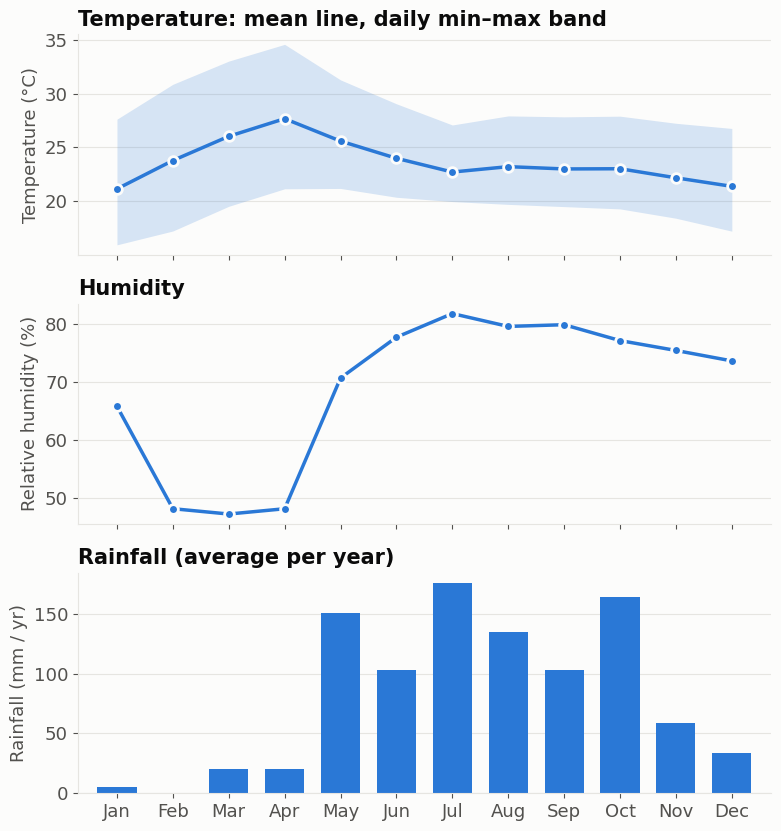

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(8, 8.5), sharex=True)
ax[0].fill_between(x, m.tmin, m.tmax, color=BLUE, alpha=0.18, lw=0)
ax[0].plot(x, m.t, color=BLUE, lw=2.5, marker="o", ms=7, mec=SURF, mew=2)
ax[0].set(ylabel="Temperature (°C)", title="Temperature: mean line, daily min–max band")
ax[1].plot(x, m.h, color=BLUE, lw=2.5, marker="o", ms=7, mec=SURF, mew=2)
ax[1].set(ylabel="Relative humidity (%)", title="Humidity")
ax[2].bar(x, m.rain, color=BLUE, width=0.7)
ax[2].set(ylabel="Rainfall (mm / yr)", title="Rainfall (average per year)")
ax[2].set_xticks(x, MONTHS)
for a in ax: a.margins(x=0.03)
fig.tight_layout(); show(fig, "01_monthly_climate")

### Chart 2: Daily AQI calendar

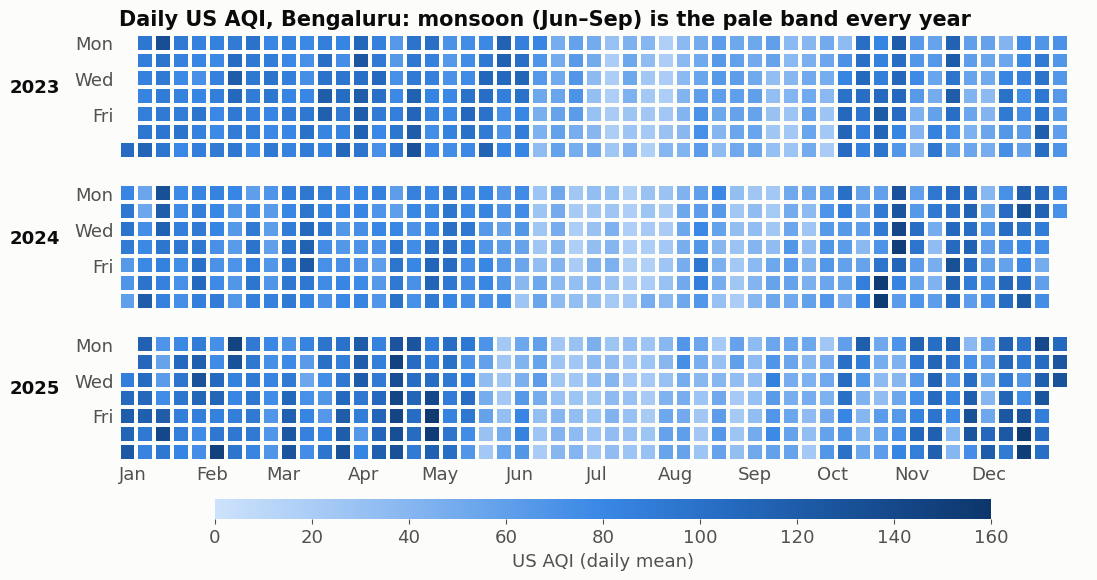

In [7]:
cmap = LinearSegmentedColormap.from_list("seq", SEQ)
fig, axs = plt.subplots(3, 1, figsize=(13, 6.3), sharex=True)
for ax, (yr, g) in zip(axs, df.groupby("year")):
    jan1 = pd.Timestamp(f"{yr}-01-01")
    wk = ((g.date - jan1).dt.days + jan1.dayofweek) // 7
    grid = np.full((7, 54), np.nan)
    grid[g.date.dt.dayofweek.values, wk.values] = g.aqi_us.values
    im = ax.pcolormesh(grid, cmap=cmap, vmin=0, vmax=160, edgecolors=SURF, linewidth=1.5)
    ax.invert_yaxis(); ax.set_aspect("equal"); ax.grid(False)
    ax.set_yticks([0.5, 2.5, 4.5], ["Mon", "Wed", "Fri"]); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_ylabel(str(yr), rotation=0, labelpad=28, fontweight="bold", color=INK)
    ticks = [((pd.Timestamp(f"{yr}-{mo:02d}-01") - jan1).days + jan1.dayofweek) / 7 + 0.5 for mo in range(1, 13)]
    ax.set_xticks(ticks, MONTHS)
axs[0].set_title("Daily US AQI, Bengaluru: monsoon (Jun–Sep) is the pale band every year")
cb = fig.colorbar(im, ax=axs, orientation="horizontal", fraction=0.04, pad=0.08, aspect=40)
cb.set_label("US AQI (daily mean)"); cb.outline.set_visible(False)
show(fig, "02_aqi_calendar")

### Chart 3: Rain vs PM2.5

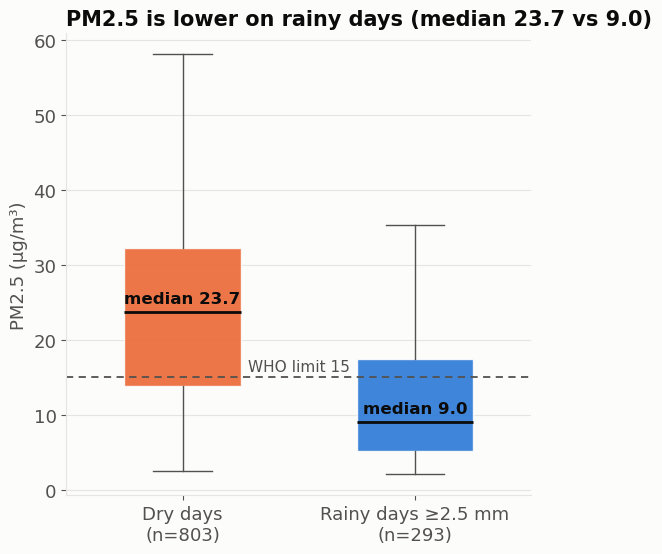

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
data = [df[~df.rainy].pm25, df[df.rainy].pm25]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=2),
                whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
for patch, c in zip(bp["boxes"], [ORANGE, BLUE]):
    patch.set(facecolor=c, edgecolor=SURF, alpha=0.9)
ax.axhline(15, color=INK2, ls=(0, (4, 3)), lw=1.3)
ax.text(1.5, 15.8, "WHO limit 15", ha="center", color=INK2, fontsize=11)
for i, d in enumerate(data, 1):
    ax.text(i, d.median() + 1.2, f"median {d.median():.1f}", ha="center", color=INK, fontsize=12, fontweight="bold")
ax.set_xticks([1, 2], [f"Dry days\n(n={len(data[0])})", f"Rainy days ≥2.5 mm\n(n={len(data[1])})"])
ax.set(ylabel="PM2.5 (µg/m³)", title=f"PM2.5 is lower on rainy days (median {data[0].median():.1f} vs {data[1].median():.1f})")
ax.grid(axis="x", visible=False)
show(fig, "03_rain_vs_pm25")

### Chart 4: Correlation heatmap

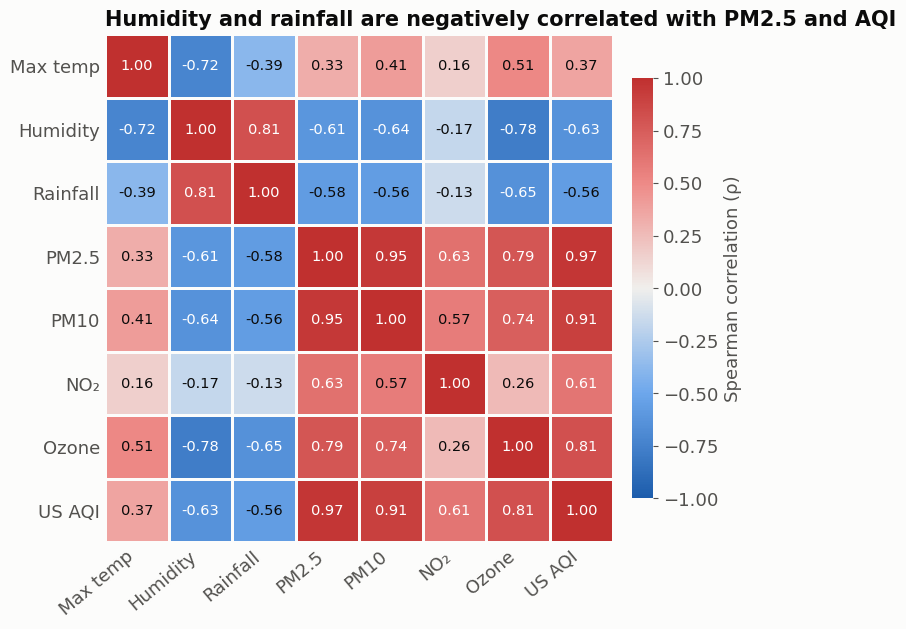

In [9]:
cols = ["temp_max", "humidity_mean", "rainfall_mm", "pm25", "pm10", "no2", "ozone", "aqi_us"]
names = ["Max temp", "Humidity", "Rainfall", "PM2.5", "PM10", "NO₂", "Ozone", "US AQI"]
c = df[cols].corr(method="spearman").values
div = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#6da7ec", MID, "#ee8a87", "#c0302f"])
fig, ax = plt.subplots(figsize=(8, 7))
q = ax.pcolormesh(c, cmap=div, vmin=-1, vmax=1, edgecolors=SURF, linewidth=2)
cb = fig.colorbar(q, ax=ax, shrink=0.78, pad=0.03)
cb.set_label("Spearman correlation (ρ)"); cb.outline.set_visible(False)
ax.invert_yaxis(); ax.set_aspect("equal"); ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(np.arange(8) + .5, names, rotation=40, ha="right"); ax.set_yticks(np.arange(8) + .5, names)
for i in range(8):
    for j in range(8):
        v = c[i, j]
        ax.text(j + .5, i + .5, f"{v:.2f}", ha="center", va="center", fontsize=10.5,
                color="#ffffff" if abs(v) > .6 else INK)
ax.set_title("Humidity and rainfall are negatively correlated with PM2.5 and AQI")
show(fig, "04_correlation")

### Chart 5: AQI category share by season

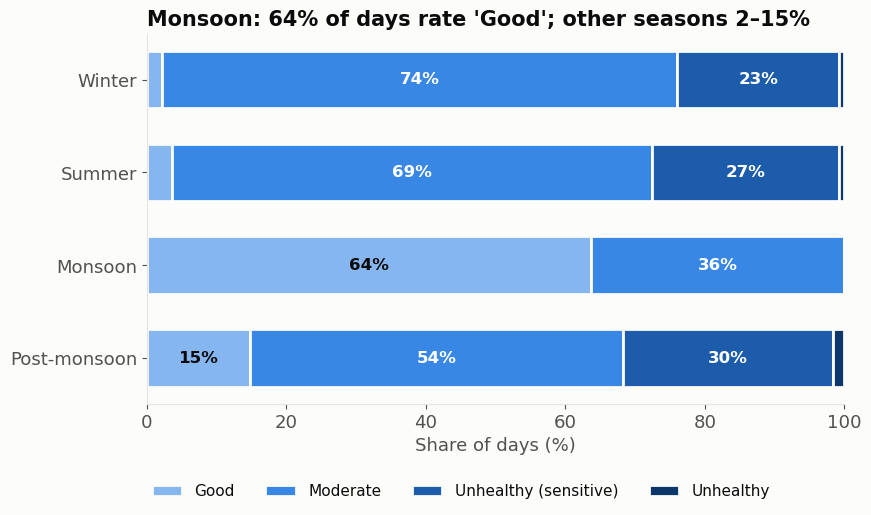

In [10]:
cats = ["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy"]
ct = pd.crosstab(df.season, df.aqi_cat).reindex(SEAS)[cats]
pct = ct.div(ct.sum(1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
left = np.zeros(4)
for cat, col in zip(cats, ORD):
    ax.barh(SEAS, pct[cat], left=left, color=col, edgecolor=SURF, linewidth=2, label=cat, height=0.62)
    for i, (l, v) in enumerate(zip(left, pct[cat])):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=12, fontweight="bold",
                    color=INK if col == ORD[0] else "#ffffff")
    left += pct[cat].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(False)
ax.set_xlabel("Share of days (%)")
ax.set_title("Monsoon: 64% of days rate 'Good'; other seasons 2–15%")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.18), fontsize=11)
show(fig, "05_aqi_category_by_season")

### Chart 6: PM2.5 by month vs rainfall

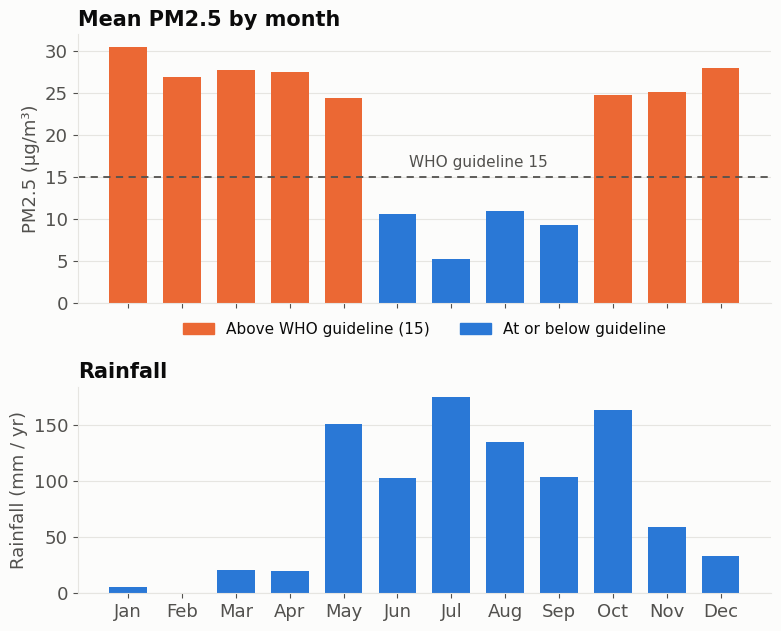

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
ax[0].bar(x, m.pm, color=[ORANGE if v > 15 else BLUE for v in m.pm], width=0.7)
ax[0].axhline(15, color=INK2, ls=(0, (4, 3)), lw=1.3)
ax[0].text(7.5, 16.2, "WHO guideline 15", ha="center", color=INK2, fontsize=11)
ax[0].set(ylabel="PM2.5 (µg/m³)", title="Mean PM2.5 by month")
ax[0].legend(handles=[Patch(color=ORANGE, label="Above WHO guideline (15)"),
                      Patch(color=BLUE, label="At or below guideline")],
             loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=11)
ax[1].bar(x, m.rain, color=BLUE, width=0.7)
ax[1].set(ylabel="Rainfall (mm / yr)", title="Rainfall")
ax[1].set_xticks(x, MONTHS)
fig.tight_layout(); show(fig, "06_pm25_vs_rain_by_month")

### Chart 7: PM2.5 time series

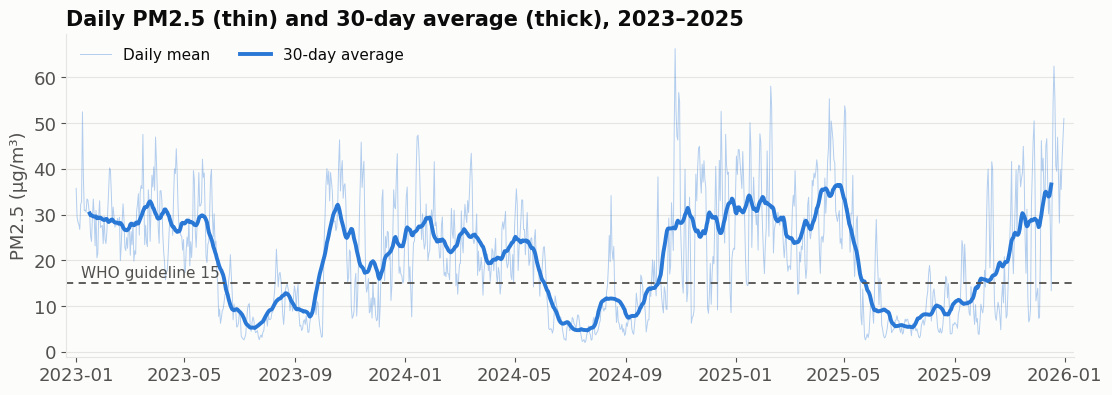

In [12]:
r = df.set_index("date")
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(r.index, r.pm25, color=BLUE, lw=0.7, alpha=0.35, label="Daily mean")
ax.plot(r.index, r.pm25.rolling(30, center=True).mean(), color=BLUE, lw=2.8, label="30-day average")
ax.legend(loc="upper left", ncol=2, fontsize=11)
ax.axhline(15, color=INK2, ls=(0, (4, 3)), lw=1.3)
ax.text(r.index[5], 16.3, "WHO guideline 15", color=INK2, fontsize=11)
ax.set(ylabel="PM2.5 (µg/m³)", title="Daily PM2.5 (thin) and 30-day average (thick), 2023–2025")
ax.margins(x=0.01)
show(fig, "07_pm25_timeseries")

## 6. Download the outputs (Colab only)

In [13]:
try:
    from google.colab import files
    import shutil
    shutil.make_archive("poster_figures", "zip", FIG_DIR)
    files.download("poster_figures.zip")
    files.download("bengaluru_daily_clean.csv")
except ImportError:
    print("Not running in Colab. Files are in ./figures and ./bengaluru_daily_clean.csv")

Not running in Colab. Files are in ./figures and ./bengaluru_daily_clean.csv
